In [3]:
# Import libraries and load the Census API key
import os
import requests
from dotenv import load_dotenv
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf

load_dotenv()
api_key = os.getenv("CENSUS_API_KEY")

# Reddit Dataset (for Emotion Detecting)

In [ ]:
url = "https://huggingface.co/datasets/mrm8488/goemotions/resolve/main/goemotions.csv"

redditDF = pd.read_csv(url)

#Prints the shape of our redditDF dataset and the first few rows

print(redditDF.shape)
print(redditDF.head())

(211225, 37)
                                                text       id  \
0                                    That game hurt.  eew5j0j   
1   >sexuality shouldn’t be a grouping category I...  eemcysk   
2     You do right, if you don't care then fuck 'em!  ed2mah1   
3                                 Man I love reddit.  eeibobj   
4  [NAME] was nowhere near them, he was by the Fa...  eda6yn6   

                author            subreddit    link_id   parent_id  \
0                Brdd9                  nrl  t3_ajis4z  t1_eew18eq   
1          TheGreen888     unpopularopinion  t3_ai4q37   t3_ai4q37   
2             Labalool          confessions  t3_abru74  t1_ed2m7g7   
3        MrsRobertshaw             facepalm  t3_ahulml   t3_ahulml   
4  American_Fascist713  starwarsspeculation  t3_ackt2f  t1_eda65q2   

    created_utc  rater_id  example_very_unclear  admiration  ...  love  \
0  1.548381e+09         1                 False           0  ...     0   
1  1.548084e+09        37  

In [ ]:
#List of columns in our dataset
columns = redditDF.columns.tolist()
print(columns)

['text', 'id', 'author', 'subreddit', 'link_id', 'parent_id', 'created_utc', 'rater_id', 'example_very_unclear', 'admiration', 'amusement', 'anger', 'annoyance', 'approval', 'caring', 'confusion', 'curiosity', 'desire', 'disappointment', 'disapproval', 'disgust', 'embarrassment', 'excitement', 'fear', 'gratitude', 'grief', 'joy', 'love', 'nervousness', 'optimism', 'pride', 'realization', 'relief', 'remorse', 'sadness', 'surprise', 'neutral']


## Visualizations

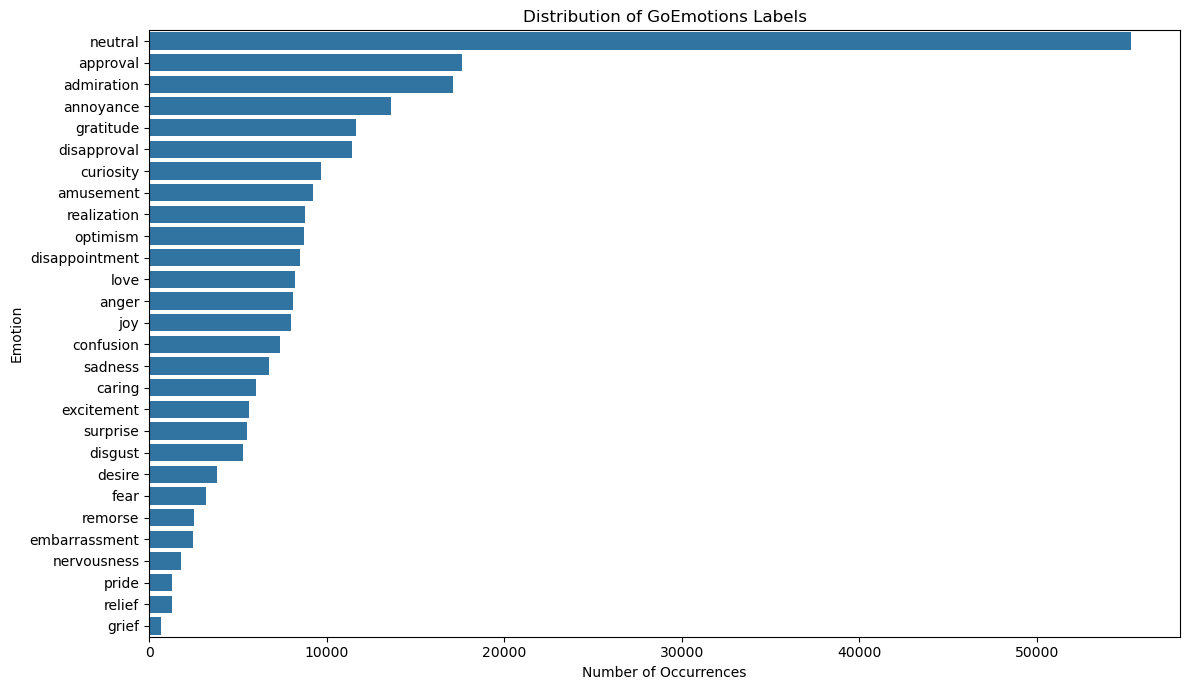

In [ ]:
# List of GoEmotions labels
emotion_cols = [
    "admiration", "amusement", "anger", "annoyance",
    "approval", "caring", "confusion", "curiosity",
    "desire", "disappointment", "disapproval", "disgust",
    "embarrassment", "excitement", "fear", "gratitude",
    "grief", "joy", "love", "nervousness", "optimism",
    "pride", "realization", "relief", "remorse",
    "sadness", "surprise", "neutral"
]

# Count how often each emotion appears
emotion_counts = redditDF[emotion_cols].sum().sort_values(
    ascending=False
)

plt.figure(figsize=(12, 7))

sns.barplot(
    x=emotion_counts.values,
    y=emotion_counts.index
)

plt.title("Distribution of GoEmotions Labels")
plt.xlabel("Number of Occurrences")
plt.ylabel("Emotion")

plt.tight_layout()
plt.show()

count    211225.000000
mean         12.997188
std           6.676105
min           1.000000
25%           7.000000
50%          13.000000
75%          18.000000
max          33.000000
Name: text_length, dtype: float64


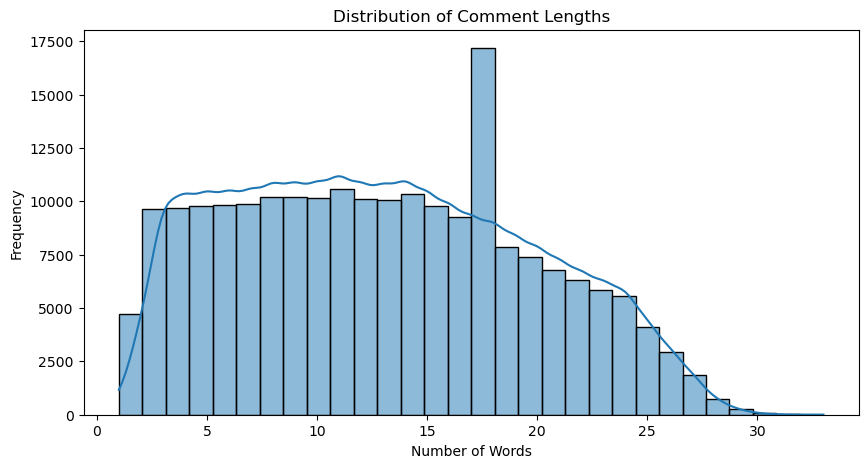

In [7]:
# Count words in each comment
redditDF["text_length"] = redditDF["text"].fillna("").apply(
    lambda x: len(x.split())
)

# Summary statistics
print(redditDF["text_length"].describe())

# Histogram
plt.figure(figsize=(10, 5))

sns.histplot(
    data=redditDF,
    x="text_length",
    bins=30,
    kde=True
)

plt.title("Distribution of Comment Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")

plt.show()

In [8]:
#Missing values in the dataset
missing_values = redditDF.isnull().sum()
print("Missing values in each column:")
print(missing_values)

Missing values in each column:
text                    0
id                      0
author                  0
subreddit               0
link_id                 0
parent_id               0
created_utc             0
rater_id                0
example_very_unclear    0
admiration              0
amusement               0
anger                   0
annoyance               0
approval                0
caring                  0
confusion               0
curiosity               0
desire                  0
disappointment          0
disapproval             0
disgust                 0
embarrassment           0
excitement              0
fear                    0
gratitude               0
grief                   0
joy                     0
love                    0
nervousness             0
optimism                0
pride                   0
realization             0
relief                  0
remorse                 0
sadness                 0
surprise                0
neutral                 0
text_le

# Context catalog

# Resources Catalog
Contains resources/excersices/help-lines in relation to emotions and context (labeled emotion_tags and context_tags). 